<a href="https://colab.research.google.com/github/Idrisadelowo/Agentic-AI-and-Foundational-Model-in-Civil-and-Building-Engineering/blob/feature%2Ftokenizers_Embedding/01_tokenizers_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-On 1: Tokenizers and Word Embeddings

Agentic AI and Foundation Models in Civil and Building Engineering, TUM, WS 2026/27

> **Disclaimer**: For teaching purposes only. Partially generated with an LLM. Not production code.

Runs on CPU, no GPU needed. On Colab: **File ▸ Upload notebook**, then run the cells top to bottom.

1. **Tokenization** - how text becomes token IDs: a small BPE tokenizer by hand, then real LLM tokenizers
2. **Word embeddings** - how token IDs become vectors that carry meaning

In [1]:
%pip install -q "transformers>=4.51" gensim
# !uv add "transformers>=4.51" gensim
# -q ensure quiet mode. ie. minimum output. Ensure quiet download and installation of transformer and gensim
# Instead of pip install, "uv add" can also be used. uv add is modern

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 34.9 MB/s eta 0:00:00


---
# Part 1 - Tokenization

A model never sees text, only **token IDs**. Three ways to cut text into tokens:

| Unit | Vocabulary | Problem |
|---|---|---|
| Characters | ~100 | very long sequences |
| Words | millions | unknown words (`Stahlbetonstütze`, `IfcRailing`) |
| **Subwords** | 50k - 250k | - |

LLMs use subwords, learned with **Byte-Pair Encoding (BPE)** (Sennrich et al., 2016).

## 1.1 BPE from scratch

1. Start with every word split into characters.
2. Count all adjacent symbol pairs.
3. Merge the most frequent pair into one new symbol.
4. Repeat. Each merge adds one entry to the vocabulary.

Our training corpus: requirements from the International Building Code (IBC).

In [4]:
import re           #re stands for "regular expression"
from collections import Counter

corpus = [
    "Egress doors shall be of the pivoted or side-hinged swinging type.",                   # IBC 1010.1.2
    "The minimum clear opening height of doors shall be not less than 80 inches (2032 mm).",  # IBC 1010.1.1
    "Stair riser heights shall be 7 inches (178 mm) maximum and 4 inches (102 mm) minimum.",  # IBC 1011.8
    "Required guards shall be not less than 42 inches (1067 mm) high.",                     # IBC 1015.3
    "Habitable spaces, other than a kitchen, shall be not less than 7 feet (2134 mm) in any plan dimension.",  # IBC 1207.1
    "Thresholds at doorways shall not exceed 3/4 inch (19.1 mm) in height above the finished floor or landing for sliding doors.",  # IBC 1010.1.7
    "The floor or landing shall be at the same elevation on each side of the door.",       # IBC 1010.1.5
    "Bathrooms, toilet rooms, kitchens, storage rooms and laundry rooms shall have a ceiling height of not less than 7 feet (2134 mm) above the finished floor.",  # IBC 1207.2
    "In buildings four or more stories above grade plane, one stairway shall extend to the roof surface.",  # IBC 1011.12
]

def split_words(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())

word_counts = Counter(w for line in corpus for w in split_words(line))
vocab = {tuple(w): n for w, n in word_counts.items()}   # each word as a tuple of characters
print(len(word_counts), "different words, e.g.", list(vocab)[:3])

93 different words, e.g. [('e', 'g', 'r', 'e', 's', 's'), ('d', 'o', 'o', 'r', 's'), ('s', 'h', 'a', 'l', 'l')]


In [12]:
def count_pairs(vocab):
    pairs = Counter()
    for symbols, n in vocab.items():
        for a, b in zip(symbols, symbols[1:]):
            pairs[a, b] += n
    return pairs

def merge(symbols, pair):
    out, i = [], 0
    while i < len(symbols):
        if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == pair:
            out.append(symbols[i] + symbols[i + 1])
            i += 2
        else:
            out.append(symbols[i])
            i += 1
    return tuple(out)

NUM_MERGES = 100
vocab = {tuple(w): n for w, n in word_counts.items()}   # start again from characters
merges = []
for step in range(NUM_MERGES):
    best, freq = count_pairs(vocab).most_common(1)[0]
    vocab = {merge(s, best): n for s, n in vocab.items()}
    merges.append(best)
    print(f"{step + 1:>2}: {best[0]!r:>8} + {best[1]!r:<8} -> {best[0] + best[1]!r:<10} ({freq}x)")

 1:      'h' + 'e'      -> 'he'       (21x)
 2:      'i' + 'n'      -> 'in'       (21x)
 3:      'o' + 'r'      -> 'or'       (16x)
 4:      'h' + 'a'      -> 'ha'       (16x)
 5:      's' + 'ha'     -> 'sha'      (9x)
 6:    'sha' + 'l'      -> 'shal'     (9x)
 7:   'shal' + 'l'      -> 'shall'    (9x)
 8:      't' + 'he'     -> 'the'      (9x)
 9:     'in' + 'g'      -> 'ing'      (9x)
10:      'e' + 's'      -> 'es'       (8x)
11:      'o' + 'or'     -> 'oor'      (8x)
12:      'm' + 'm'      -> 'mm'       (7x)
13:      'a' + 'n'      -> 'an'       (7x)
14:      'b' + 'e'      -> 'be'       (6x)
15:      'o' + 't'      -> 'ot'       (6x)
16:      'c' + 'he'     -> 'che'      (6x)
17:     'es' + 's'      -> 'ess'      (5x)
18:      'd' + 'oor'    -> 'door'     (5x)
19:      'o' + 'f'      -> 'of'       (5x)
20:      'i' + 'g'      -> 'ig'       (5x)
21:     'ig' + 'h'      -> 'igh'      (5x)
22:      'n' + 'ot'     -> 'not'      (5x)
23:      't' + 'ha'     -> 'tha'      (5x)
24:    

The merges are the tokenizer. To tokenize **new** text, apply them in the same order:

In [13]:
def bpe_tokenize(text):
    tokens = []
    for word in split_words(text):
        symbols = tuple(word)
        for pair in merges:
            symbols = merge(symbols, pair)
        tokens += symbols
    return tokens

sentence = "The handrail shall be at least 1.0 m high."
tokens = bpe_tokenize(sentence)
print(len(tokens), "tokens:", tokens)

20 tokens: ['the', 'ha', 'n', 'd', 'r', 'a', 'il', 'shall', 'be', 'at', 'le', 'a', 'st', '1', '.', '0', 'm', 'h', 'igh', '.']


**Your turn**
- Set `NUM_MERGES` to 100 and rerun the two cells. Which words become single tokens?
- Which words of the handrail sentence stay split? Why?

Single token words are
"the
shall
be
at"


After increasing NUM_MERGES to 100, many common words such as shall, height, inches, doors, floor, minimum, kitchen, landing, and egress become single tokens. The words handrail and least, along with the number expression 1.0 m and high, remain split because they occur less frequently in the corpus. BPE prioritises merging the most frequent character pairs, so rare words receive fewer merges and often remain broken into subword tokens.

## 1.2 Real tokenizers

Two tokenizers trained on huge corpora: **GPT-2** (2019, 50k tokens) and **Qwen3** (2025, 151k tokens).
A leading space is part of the token: `' shall'` and `'shall'` are two different tokens.

In [14]:
from transformers import AutoTokenizer

tokenizers = {
    "GPT-2": AutoTokenizer.from_pretrained("openai-community/gpt2"),
    "Qwen3": AutoTokenizer.from_pretrained("Qwen/Qwen3-0.6B"),
}

print(sentence)

ids = tokenizers["Qwen3"](sentence)["input_ids"]
for i in ids:
    print(f"{i:>7} -> {tokenizers['Qwen3'].decode([i])!r}")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

The handrail shall be at least 1.0 m high.
    785 -> 'The'
   1424 -> ' hand'
  75635 -> 'rail'
   4880 -> ' shall'
    387 -> ' be'
    518 -> ' at'
   3245 -> ' least'
    220 -> ' '
     16 -> '1'
     13 -> '.'
     15 -> '0'
    296 -> ' m'
   1550 -> ' high'
     13 -> '.'


**Inside the vocabulary.** IDs 0-255 are single bytes. After that, IDs follow the merge order: low IDs are
early, frequent merges. Special tokens (chat roles, tool calls) sit at the end.

In [15]:
for name, tok in tokenizers.items():
    print(f"{name}: {len(tok):,} tokens")
    for start in [0, 256, 1000, 10000, len(tok) - 12]:
        print(f"  {start:>7}: {[tok.decode([i]) for i in range(start, start + 12)]}")

GPT-2: 50,257 tokens
        0: ['!', '"', '#', '$', '%', '&', "'", '(', ')', '*', '+', ',']
      256: [' t', ' a', 'he', 'in', 're', 'on', ' the', 'er', ' s', 'at', ' w', ' o']
     1000: ['ale', ' Se', ' If', '//', ' Le', ' ret', ' ref', ' trans', 'ner', 'ution', 'ters', ' take']
    10000: [' pocket', ' Inv', 'Download', ' Crime', ' bene', ' Guide', ' Assembly', ' parameters', 'IE', ' Alexander', ' concert', ' Sche']
    50245: [' Hitman', 'Commission', ' (/', '…."', 'Compar', ' amplification', 'ominated', ' regress', ' Collider', ' informants', ' gazed', '<|endoftext|>']
Qwen3: 151,669 tokens
        0: ['!', '"', '#', '$', '%', '&', "'", '(', ')', '*', '+', ',']
      256: ['  ', '    ', 'in', ' t', '        ', 'er', '   ', 'on', ' a', 're', 'at', 'st']
     1000: ['atus', 'Th', 'itle', 'rit', 'void', '().', '(\n', ' off', ' other', ' &&', "';\n", 'ms']
    10000: [' rise', ' kernel', '::$', '.Q', ' offering', 'decl', ' CS', ' listed', ' mostly', 'enger', ' blocks', 'olo']
   151

In [17]:
examples = [
    "The handrail shall be at least 1.0 m high.",
    "Das Geländer muss mindestens 1,0 m hoch sein.",
    "Stahlbetonstütze",
    "IfcRailing",
    "Eurocode 2 (EN 1992-1-1)",
    "2032.5" #task 2
]
for text in examples:
    print(text)
    for name, tok in tokenizers.items():
        pieces = [tok.decode([i]) for i in tok(text)["input_ids"]]
        print(f"  {name:<6} {len(pieces):>2} tokens  {pieces}")

The handrail shall be at least 1.0 m high.
  GPT-2  13 tokens  ['The', ' hand', 'rail', ' shall', ' be', ' at', ' least', ' 1', '.', '0', ' m', ' high', '.']
  Qwen3  14 tokens  ['The', ' hand', 'rail', ' shall', ' be', ' at', ' least', ' ', '1', '.', '0', ' m', ' high', '.']
Das Geländer muss mindestens 1,0 m hoch sein.
  GPT-2  19 tokens  ['D', 'as', ' Gel', 'ä', 'nder', ' m', 'uss', ' mind', 'est', 'ens', ' 1', ',', '0', ' m', ' h', 'och', ' se', 'in', '.']
  Qwen3  15 tokens  ['Das', ' Gel', 'änder', ' muss', ' min', 'dest', 'ens', ' ', '1', ',', '0', ' m', ' hoch', ' sein', '.']
Stahlbetonstütze
  GPT-2   8 tokens  ['St', 'ahl', 'bet', 'on', 'st', 'ü', 't', 'ze']
  Qwen3   6 tokens  ['St', 'ahl', 'bet', 'on', 'stüt', 'ze']
IfcRailing
  GPT-2   4 tokens  ['If', 'c', 'R', 'ailing']
  Qwen3   4 tokens  ['If', 'c', 'R', 'ailing']
Eurocode 2 (EN 1992-1-1)
  GPT-2  11 tokens  ['Euro', 'code', ' 2', ' (', 'EN', ' 1992', '-', '1', '-', '1', ')']
  Qwen3  16 tokens  ['Euro', 'code', ' ', '

Same meaning, different cost: German and domain terms split into more tokens. The larger Qwen3
vocabulary helps for German, but Qwen3 also splits every number into single digits. Token count sets
the price of an API call and how much fits into the context window.

**Your turn**
- Find a building term that GPT-2 splits into 5 or more tokens.
# 8 tokens  ['St', 'ahl', 'bet', 'on', 'st', 'ü', 't', 'ze']
- Tokenize a number such as `2032.5`. How are digits handled by each tokenizer?
# GPT-2   4 tokens  ['20', '32', '.', '5']
# Qwen3   6 tokens  ['2', '0', '3', '2', '.', '5']
- What is the benefit of splitting numbers into single digits?
# better generalisation to unseen numbers and a smaller vocabulary.
- Why are runs of spaces (`'    '`) among the first Qwen3 merges, but not in GPT-2?
# Qwen3: spaces are separate tokens and are frequently merged.
# GPT-2: spaces are usually attached to the following word, so separate space merges are less important.

---
# Part 2 - Word Embeddings

A token ID is just an index. The model turns it into a **vector** by looking it up in a table, the
**embedding**. **word2vec** (Mikolov et al., 2013) learns these vectors from one idea, the
**distributional hypothesis**: words in similar contexts get similar vectors. "You shall know a word by the
company it keeps" (Firth, 1957). There are many ways to learn them:

- **word2vec CBOW**: a small neural net predicts the middle word from its neighbours.
- **word2vec skip-gram**: the same net predicts the neighbours from the middle word.
- **GloVe** (Pennington et al., 2014): count word pairs in the corpus, then fit vectors to the counts.

We load GloVe vectors trained on Wikipedia:
400k words, 100 numbers each (~180 MB download).

In [ ]:
from huggingface_hub import hf_hub_download
from gensim.models import KeyedVectors

repo = "fse/glove-wiki-gigaword-100"
path = hf_hub_download(repo, "glove-wiki-gigaword-100.model")
hf_hub_download(repo, "glove-wiki-gigaword-100.model.vectors.npy")
wv = KeyedVectors.load(path)

print(len(wv), "words, vector size", wv.vector_size)
print("most frequent :", list(wv.key_to_index)[:15])
print("least frequent:", list(wv.key_to_index)[-5:])
print(wv["concrete"][:10], "...")

glove-wiki-gigaword-100.model: reconstructing file:   0%|          |  0.00B / 21.5MB            

glove-wiki-gigaword-100.model: downloading bytes:           |  0.00B            

glove-wiki-gigaword-100.model.vectors.np(…): reconstructing file:   0%|          |  0.00B /  160MB            

glove-wiki-gigaword-100.model.vectors.np(…): downloading bytes:           |  0.00B            

400000 words, vector size 100
most frequent : ['the', ',', '.', 'of', 'to', 'and', 'in', 'a', '"', "'s", 'for', '-', 'that', 'on', 'is']
least frequent: ['chanty', 'kronik', 'rolonda', 'zsombor', 'sandberger']
[ 0.078469  1.1473   -0.66296   0.78508  -0.14958  -0.88527  -0.86749
  0.30452   0.3958    0.67427 ] ...


## 2.1 Similar words

Similarity is the cosine of the angle between two vectors: 1 = same direction, 0 = unrelated.

In [ ]:
for word in ["concrete", "steel", "stair", "bridge", "beam"]:
    print(f"{word:<9}", [w for w, _ in wv.most_similar(word, topn=6)])

concrete  ['walls', 'steps', 'brick', 'building', 'blocks', 'slabs']
steel     ['iron', 'aluminum', 'stainless', 'metal', 'aluminium', 'cement']
stair     ['staircase', 'staircases', 'stairway', 'railings', 'stairs', 'balustrade']
bridge    ['road', 'bridges', 'tunnel', 'canal', 'crossing', 'railway']
beam      ['beams', 'laser', 'horizontal', 'vertical', 'velocity', 'surface']


`stair` and `stairs` rarely appear next to each other. They are close because they keep the same company,
e.g. `climb`, `landing`, `railing`. The model never sees spelling: two words are just two rows of counts.

Look at `beam`: its neighbours mix structures (`horizontal`, `vertical`) with physics (`laser`, `velocity`).
A word gets **one vector**, whatever its context. Transformers fix this: attention turns the vector of
`beam` into a different vector next to `steel` than next to `laser` (Notebook 2).

## 2.2 Vector arithmetic

Directions in the space carry meaning: `king - man + woman` lands near `queen`.

In [ ]:
def analogy(a, b, c):
    """a - b + c"""
    result = wv.most_similar(positive=[a, c], negative=[b], topn=3)
    print(f"{a} - {b} + {c} = {[w for w, _ in result]}")

analogy("king", "man", "woman")
analogy("paris", "france", "germany")
analogy("bridge", "river", "road")

king - man + woman = ['queen', 'monarch', 'throne']
paris - france + germany = ['berlin', 'frankfurt', 'vienna']
bridge - river + road = ['lane', 'highway', 'lanes']


## 2.3 The embedding space in 2D

100 dimensions projected to 2 with PCA (principal component analysis).

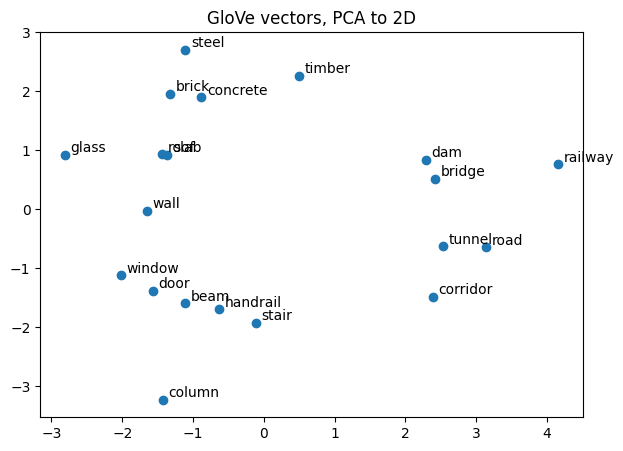

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

words = ["concrete", "steel", "timber", "brick", "glass",
         "beam", "column", "wall", "slab", "roof",
         "door", "window", "stair", "handrail", "corridor",
         "bridge", "tunnel", "road", "railway", "dam"]
X = wv[words] - wv[words].mean(axis=0)
xy = X @ np.linalg.svd(X, full_matrices=False)[2][:2].T   # PCA: project onto the top 2 directions

plt.figure(figsize=(7, 5))
plt.scatter(xy[:, 0], xy[:, 1])
for (x, y), w in zip(xy, words):
    plt.annotate(w, (x, y), xytext=(4, 2), textcoords="offset points")
plt.title("GloVe vectors, PCA to 2D")
plt.show()

**Your turn**
- Add five words of your own to `words`. Do they land near the group you expect?
- Find an analogy that works and one that fails, e.g. `analogy("steel", "metal", "wood")`.
- Which pair is closer: `wv.similarity("concrete", "cement")` or `wv.similarity("concrete", "abstract")`? Why does the second one score at all?

---
## Solutions

<details>
<summary>Click to show</summary>

**1.1** With 100 merges, frequent words such as `shall`, `less`, `than`, `inches` become one token.
`handrail` stays split: it never appears in the corpus, so BPE builds it from smaller pieces it has seen.
That is how BPE handles unknown words - nothing is ever out of vocabulary.

**1.2** German compounds split most, e.g. `Stahlbetonstütze` into 8 GPT-2 tokens. GPT-2 merges digit groups
(`' 1992'` is one token, other numbers split differently); Qwen3 always uses one token per digit, so every
number is split the same way.
Benefit of single digits: GPT-2 splits `2032` into `20|32` but `2134` into `2|134`, so the same digit lands in
different tokens. With one token per digit, each position (thousands, hundreds, ...) is always one token,
and the model can learn arithmetic and comparisons digit by digit, as on paper. Cost: more tokens per number.
Runs of spaces: indentation in source code. Qwen3 was trained on much more code than GPT-2.

**2.3** `concrete` also means "not abstract", so the vector of `concrete` mixes both senses - the same
one-vector-per-word problem as `beam`.

</details>

---
## References

- Sennrich, R., Haddow, B., & Birch, A. (2016). Neural Machine Translation of Rare Words with Subword Units. arXiv:1508.07909
- Mikolov, T., Chen, K., Corrado, G., & Dean, J. (2013). Efficient Estimation of Word Representations in Vector Space. arXiv:1301.3781
- Firth, J. R. (1957). A Synopsis of Linguistic Theory, 1930-1955. In Studies in Linguistic Analysis, pp. 10-32. Blackwell
- Pennington, J., Socher, R., & Manning, C. (2014). GloVe: Global Vectors for Word Representation. EMNLP 2014
- Requirements in 1.1: International Building Code (IBC), sections as listed